# HW5 – Fraud Model: Random Forest and XGBoost vs. HW4 Logistic Regression
**Team 1 – Slow Burn**

Goal: predict at the moment an application is submitted whether it will become confirmed fraud, using two models
beyond logistic regression (Deck 9), and compare them with the HW4 logistic regression on the same data and split.

1. Load data · 2. Target and random 75/25 split · 3. Features · 4. Model matrices · 5. HW4 logistic baseline ·
6. XGBoost · 7. Random forest · 8. Assessment and costs (Deck 7) · 9. Model comparison

## 1. Load the data

In [1]:
# XGBoost and Optuna are the only packages beyond the course environment (Deck 9 installs optuna the same way).
# Installs them only if they are missing.
import importlib.util
if importlib.util.find_spec("xgboost") is None or importlib.util.find_spec("optuna") is None:
    %pip install xgboost optuna --quiet

In [2]:
import warnings, glob, os, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import optuna
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
                             average_precision_score)
from sklearn.inspection import PartialDependenceDisplay

SEED = 1234
DATA_DIR = "DFS_Table"          # folder with the 43 exported CSVs (same folder as this notebook)
OUT_DIR = "outputs_hw5"         # tables and figures for the memo are written here
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 60)

def load(name, **kw):
    '''Read a table from the DFS export. Accepts plain names (applications.csv) or DBeaver's
    timestamped names (applications_202611041545.csv).'''
    files = sorted(glob.glob(f"{DATA_DIR}/{name}.csv")) or sorted(glob.glob(f"{DATA_DIR}/{name}_2*.csv"))
    return pd.read_csv(files[0], low_memory=False, **kw)

def ts(series):
    '''Timestamp column -> timezone-aware datetime (UTC).'''
    return pd.to_datetime(series, utc=True, format="mixed")

def is_true(s):
    return s.astype(str).str.lower().eq("true")

t0 = time.time()
apps       = load("applications")
applicants = load("applicants")
devices    = load("devices")
domains    = load("email_domains")
sessions   = load("web_sessions")
ref_codes  = load("referral_codes")
creatives  = load("creatives")
offers     = load("offer_versions")
inv        = load("fraud_investigations")
inv_events = load("fraud_investigation_events")
customers  = load("customers")
branches   = load("branches")
geos       = load("geographies")
creators   = load("creators_publishers")
accounts   = load("accounts")
incentives = load("incentive_payments")
adf        = load("application_decision_features")
entities   = load("entities")
ent_links  = load("application_entity_links")

# marketing_touches is ~680 MB: keep only touches tied to an applicant and summarize to one row per application
# (earliest touch BEFORE the application and how many touches came before it). Filter on touch_ts, not ingestion_ts.
mt = pd.read_csv(sorted(glob.glob(f"{DATA_DIR}/marketing_touches*.csv"))[0],
                 usecols=["applicant_id", "touch_ts"]).dropna(subset=["applicant_id"])
mt["touch_ts"] = ts(mt["touch_ts"])
_m = apps[["application_id", "applicant_id", "application_ts"]].assign(application_ts=lambda d: ts(d["application_ts"]))
_m = _m.merge(mt, on="applicant_id")
_m = _m[_m["touch_ts"] <= _m["application_ts"]]
first_touch = (_m.groupby("application_id").agg(first_touch_ts=("touch_ts", "min"), n_touches_before=("touch_ts", "size"))
               .reset_index())
del mt, _m

apps["app_ts"] = ts(apps["application_ts"])
print(f"Applications: {len(apps):,} | Applicants: {len(applicants):,} | Entities: {len(entities):,} | "
      f"Entity links: {len(ent_links):,}")
print(f"Latest application: {apps['app_ts'].max():%Y-%m-%d} | loaded in {time.time()-t0:.0f}s")

Applications: 285,046 | Applicants: 246,235 | Entities: 709,495 | Entity links: 1,090,458
Latest application: 2026-10-31 | loaded in 21s


## 2. Target and train/test split
An application is fraud (1) if any of its investigations ends at `confirmed`; everything else is 0.

In [3]:
inv_events["event_ts"] = ts(inv_events["event_ts"])
latest = (inv_events.sort_values("event_ts").groupby("investigation_id").tail(1)[["investigation_id", "status", "fraud_type"]])
inv_status = inv.merge(latest, on="investigation_id")
fraud_ids = set(inv_status.loc[inv_status["status"] == "confirmed", "application_id"])
apps["fraud"] = apps["application_id"].isin(fraud_ids).astype(int)

# When was each fraud confirmed, and when did DFS actually KNOW it (event AND ingestion)? Used for point-in-time features.
conf = (inv_events[inv_events["status"] == "confirmed"]
        .assign(ing=lambda d: ts(d["ingestion_ts"]))
        .merge(inv[["investigation_id", "application_id"]], on="investigation_id")
        .groupby("application_id").agg(confirmed_ts=("event_ts", "min"), conf_ing=("ing", "min")))
apps = apps.merge(conf, left_on="application_id", right_index=True, how="left")
apps["known_ts"] = apps[["confirmed_ts", "conf_ing"]].max(axis=1).dt.tz_convert(None)
# When was an investigation first OPENED on each application, as known to DFS (opened AND ingested)? Opening happens
# weeks before confirmation, so "a linked application is under investigation" is a much faster signal than "confirmed".
inv_open = (inv.assign(o=lambda d: ts(d["opened_ts"]), ing=lambda d: ts(d["ingestion_ts"]))
              .assign(known=lambda d: d[["o", "ing"]].max(axis=1).dt.tz_convert(None)).groupby("application_id")["known"].min())
apps["inv_open_known"] = apps["application_id"].map(inv_open)

apps["month"] = apps["app_ts"].dt.tz_convert("America/New_York").dt.strftime("%Y-%m")
by_month = apps.groupby("month").agg(applications=("fraud", "size"), fraud_rate=("fraud", "mean"))

lag = (apps.dropna(subset=["confirmed_ts"])["confirmed_ts"] - apps.dropna(subset=["confirmed_ts"])["app_ts"]).dt.days
print("Days from application to confirmation (confirmed cases):")
print(lag.quantile([0.25, 0.5, 0.75, 0.9, 0.95]).round(0).to_string())
print(f"\nOverall fraud rate: {apps['fraud'].mean():.2%}")
by_month.tail(10).style.format({"fraud_rate": "{:.2%}", "applications": "{:,}"})

Days from application to confirmation (confirmed cases):
0.25    15.0
0.50    25.0
0.75    42.0
0.90    63.0
0.95    75.0

Overall fraud rate: 5.03%


,applications,fraud_rate
month,,
2026-01,"7,805",3.97%
2026-02,"7,093",4.47%
2026-03,"7,811",4.37%
2026-04,"7,619",4.38%
2026-05,"7,856",4.46%
2026-06,"7,616",4.08%
2026-07,"35,583",6.16%
2026-08,"37,544",7.92%
2026-09,"36,308",6.45%


Confirmation takes a median of about 25 days, so the newest months are not mature yet. We model **January 2025 –
August 2026**, keep **September 2026** as an extra check on the newest month, and drop October. The split is a random
75% / 25% (class code, same as HW4), made before any feature is built so data-based statistics come from training only.

In [4]:
MODEL_END, CHECK_MONTH = "2026-08", "2026-09"
model_ids = apps.loc[apps["month"] <= MODEL_END, "application_id"]
train_ids, test_ids = train_test_split(model_ids, test_size=0.25, random_state=SEED)
train_ids, test_ids = set(train_ids), set(test_ids)
print(f"Train: {len(train_ids):,} applications (75%) | Test: {len(test_ids):,} (25%) | "
      f"September 2026 check: {(apps['month'] == CHECK_MONTH).sum():,}")

Train: 158,994 applications (75%) | Test: 52,998 (25%) | September 2026 check: 36,308


## 3. Features
Every feature uses only information dated before the application was submitted (no leakage). Fraud history counts only
if the confirmation was recorded before the application. Sections 3a–3e are the HW3/HW4 feature ideas; 3f adds the
shared phone/address/payout links (empty in the HW4 data); 3g adds raw application fields and categorical codes.

In [5]:
apps = apps.merge(devices[["device_id", "device_hash", "first_seen_ts", "is_emulator", "device_os", "device_type", "browser_family"]],
                  on="device_id", how="left")
apps["device_first_seen"] = ts(apps["first_seen_ts"])
apps = apps.merge(applicants[["applicant_id", "customer_id", "date_of_birth", "home_zip3", "salary_usd", "employment_status", "housing_status"]], on="applicant_id", how="left")
apps = apps.merge(domains[["email_domain", "first_seen_date", "domain_type", "mx_valid", "registrar_country"]], on="email_domain", how="left")
apps = apps.merge(sessions[["session_id", "session_start_ts", "page_count", "ip_country_code", "keep_alive", "referrer_domain"]], on="session_id", how="left")
apps = apps.merge(customers[["customer_id", "customer_segment", "is_employee"]], on="customer_id", how="left")
apps = apps.merge(ref_codes[["referral_code_id", "owner_customer_id"]], on="referral_code_id", how="left")
apps = apps.merge(creatives[["creative_id", "offer_id", "creator_id"]], on="creative_id", how="left")
apps = apps.merge(first_touch, on="application_id", how="left")
apps = apps.merge(adf[["application_id", "date_of_birth_distinct_emails_4w", "device_distinct_emails_8w", "zip_count_4w",
                       "velocity_6h", "velocity_24h", "velocity_4w", "bank_branch_count_8w"]], on="application_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["ts_naive"] = apps["app_ts"].dt.tz_convert(None)
apps["day"] = apps["ts_naive"].dt.floor("D")
apps["confirmed_naive"] = apps["confirmed_ts"].dt.tz_convert(None)

def count_prior(df, key, days=None, hours=None, distinct_col=None, exclude_same=None):
    '''For each row: how many earlier rows share `key` inside [t - window, t).
    distinct_col: count distinct values of this column instead of rows.
    exclude_same: ignore earlier rows with the same value in this column (e.g. same applicant).'''
    window = np.timedelta64(days, "D") if days else np.timedelta64(hours, "h")
    out = pd.Series(0.0, index=df.index)
    for _, g in df.dropna(subset=[key]).groupby(key):
        if len(g) == 1:
            continue
        t = g["ts_naive"].to_numpy()
        lo = np.searchsorted(t, t - window); hi = np.searchsorted(t, t)
        if distinct_col is None and exclude_same is None:
            out.loc[g.index] = hi - lo; continue
        vals = g[distinct_col or exclude_same].to_numpy()
        same = g[exclude_same].to_numpy() if exclude_same else None
        res = []
        for i in range(len(g)):
            w = vals[lo[i]:hi[i]]
            if exclude_same:
                w = w[same[lo[i]:hi[i]] != same[i]]
            res.append(len(set(w)) if distinct_col else len(w))
        out.loc[g.index] = res
    return out

def prior_rate_by_group(df, key, start_days, end_days, prior_weight=None, prior_rate=None):
    '''Point-in-time fraud rate for a group (campaign, creator...): applications dated in
    [t - start_days, t - end_days) whose fraud was CONFIRMED BEFORE t. Day-by-day table so it stays fast.'''
    out = pd.Series(np.nan, index=df.index)
    for _, g in df.dropna(subset=[key]).groupby(key):
        days = pd.date_range(g["day"].min(), g["day"].max() + pd.Timedelta(days=1), freq="D")
        idx = {d: i for i, d in enumerate(days)}; n = len(days)
        apps_per_day = np.zeros(n); np.add.at(apps_per_day, g["day"].map(idx).to_numpy(), 1)
        conf_m = np.zeros((n, n))
        cg = g.dropna(subset=["confirmed_naive"])
        cd = cg["confirmed_naive"].dt.floor("D").clip(upper=days[-1])
        np.add.at(conf_m, (cg["day"].map(idx).to_numpy(), cd.map(idx).to_numpy()), 1)
        conf_cum = conf_m.cumsum(axis=1)
        res_day = np.full(n, np.nan)
        for d in range(n):
            a0, a1 = max(0, d - start_days), max(0, d - end_days)
            if a1 <= a0: continue
            n_apps = apps_per_day[a0:a1].sum()
            n_conf = conf_cum[a0:a1, d - 1].sum() if d > 0 else 0
            if prior_weight: res_day[d] = (n_conf + prior_weight * prior_rate) / (n_apps + prior_weight)
            elif n_apps > 0: res_day[d] = n_conf / n_apps
        out.loc[g.index] = res_day[g["day"].map(idx).to_numpy()]
    return out

### 3a. Identity & email

In [6]:
t0 = time.time()
age_months = (apps["ts_naive"] - pd.to_datetime(apps["date_of_birth"])).dt.days / 30.44
addr = (apps["prev_address_months_count"].where(apps["prev_address_months_count"] >= 0, 0)
        + apps["current_address_months_count"].where(apps["current_address_months_count"] >= 0, 0))
apps["addr_history_exceeds_age"] = ((addr - age_months) > 0).astype(float)
apps["email_domain_age_days"] = (apps["ts_naive"] - pd.to_datetime(apps["first_seen_date"])).dt.days.clip(lower=0)
apps["disposable_email_domain"] = np.where(apps["domain_type"].isna(), np.nan, (apps["domain_type"] == "disposable").astype(float))
apps["email_no_mail_server"] = np.where(apps["mx_valid"].isna(), np.nan, (~is_true(apps["mx_valid"])).astype(float))
apps["email_domain_risk_flag"] = np.where(apps["domain_type"].isna(), np.nan,
                                          ((apps["domain_type"] == "disposable") | ~is_true(apps["mx_valid"])).astype(float))
apps["name_email_similarity_score"] = apps["name_email_similarity"]
apps["bank_history_vs_age"] = apps["bank_months_count"].where(apps["bank_months_count"] >= 0) / age_months
apps["thin_credit_file"] = is_true(apps["thin_file_flag"]).astype(float)
apps["phone_mobile_ok"] = is_true(apps["phone_mobile_valid"]).astype(float)
apps["phone_home_ok"] = is_true(apps["phone_home_valid"]).astype(float)
apps["no_valid_phone"] = (~is_true(apps["phone_home_valid"]) & ~is_true(apps["phone_mobile_valid"])).astype(float)
apps["dob_email_velocity"] = apps["date_of_birth_distinct_emails_4w"]

# 0-4 email risk score: free/disposable, no MX, domain < 90 days old, name-email similarity in bottom 20% (training set)
sim_cut = apps.loc[apps["application_id"].isin(train_ids), "name_email_similarity"].quantile(0.2)
apps["email_risk_score"] = np.where(apps["domain_type"].isna(), np.nan,
    apps["domain_type"].isin(["free", "disposable"]).astype(int) + (~is_true(apps["mx_valid"])).astype(int)
    + (apps["email_domain_age_days"] < 90).astype(int) + (apps["name_email_similarity"] <= sim_cut).astype(int))

# email-domain surge: domain's share of applications in the prior 24h / its share in the 28 days before that
t_all = apps["ts_naive"].to_numpy()
tot_24h = np.searchsorted(t_all, t_all) - np.searchsorted(t_all, t_all - np.timedelta64(24, "h"))
tot_28d = (np.searchsorted(t_all, t_all - np.timedelta64(24, "h")) - np.searchsorted(t_all, t_all - np.timedelta64(24 + 28 * 24, "h")))
dom_24h = count_prior(apps, "email_domain", hours=24)
dom_28d = count_prior(apps, "email_domain", hours=24 + 28 * 24) - dom_24h
apps["email_domain_surge"] = np.where(apps["email_domain"].notna(),
                                      (dom_24h / np.maximum(tot_24h, 1)) / np.maximum(dom_28d / np.maximum(tot_28d, 1), 0.0001), np.nan)
print(f"3a done in {time.time()-t0:.0f}s")

3a done in 5s


### 3b. Device & network linkage

In [7]:
t0 = time.time()
# Shared device applicants (90d) and link to past confirmed fraud through the device
apps["shared_device_applicants_90d"] = 0.0; apps["device_linked_to_past_fraud"] = 0.0; apps["device_confirmed_fraud_count"] = 0.0
apps["device_open_investigations"] = 0.0
for _, g in apps.dropna(subset=["device_hash"]).groupby("device_hash"):
    if len(g) == 1: continue
    t = g["ts_naive"].to_numpy(); who = g["applicant_id"].to_numpy(); known = g["known_ts"].to_numpy()
    lo = np.searchsorted(t, t - np.timedelta64(90, "D"))
    shared = [len(set(who[lo[i]:i][who[lo[i]:i] != who[i]])) for i in range(len(g))]
    n_known = [int(np.sum(known[:i] < t[i])) for i in range(len(g))]          # confirmed AND ingested before t
    opn = g["inv_open_known"].to_numpy()
    n_open = [int(np.sum((opn[:i] < t[i]) & (who[:i] != who[i]))) for i in range(len(g))]   # investigation OPENED on another applicant's app on this device
    apps.loc[g.index, "shared_device_applicants_90d"] = shared
    apps.loc[g.index, "device_confirmed_fraud_count"] = n_known
    apps.loc[g.index, "device_linked_to_past_fraud"] = [float(k > 0) for k in n_known]
    apps.loc[g.index, "device_open_investigations"] = n_open

apps["device_age_days"] = ((apps["app_ts"] - apps["device_first_seen"]).dt.total_seconds() / 86400).clip(lower=0)
apps["device_applicants_7d"] = count_prior(apps, "device_hash", days=7, distinct_col="applicant_id", exclude_same="applicant_id")
apps["device_apps_90d"] = count_prior(apps, "device_id", days=90)
apps["device_apps_24h"] = count_prior(apps, "device_id", hours=24)
b2_30d = count_prior(apps, "device_id", days=30)
apps["device_app_burst"] = np.where(apps["device_id"].notna(), apps["device_apps_24h"] / (b2_30d / 30 + 0.1), np.nan)
# distinct channels used on this device in the prior 30 days, including this application
k4 = pd.Series(1.0, index=apps.index)
for _, g in apps.dropna(subset=["device_hash"]).groupby("device_hash"):
    if len(g) == 1: continue
    t = g["ts_naive"].to_numpy(); ch = g["application_channel"].to_numpy()
    lo = np.searchsorted(t, t - np.timedelta64(30, "D"))
    k4.loc[g.index] = [len(set(ch[lo[i]:i + 1])) for i in range(len(g))]
apps["device_channels_30d"] = k4

real_os = {"Android", "iOS", "Windows", "macOS", "Linux", "ChromeOS"}
apps["emulator_or_fake_os"] = np.where(apps["device_id"].isna(), np.nan,
                                       (is_true(apps["is_emulator"]) | ~apps["device_os"].isin(real_os)).astype(float))
# browser/OS mismatch (Safari on Android, Edge on iOS, ...), added in HW5
mismatch = ((apps["device_os"] == "Android") & (apps["browser_family"] == "Safari")) | \
           ((apps["device_os"] == "iOS") & apps["browser_family"].isin(["Edge", "Internet Explorer"]))
apps["browser_os_mismatch"] = np.where(apps["device_id"].isna(), np.nan, mismatch.astype(float))
apps["device_distinct_emails_8w_f"] = apps["device_distinct_emails_8w"]                                              # bank's feature
# the same applicant's EARLIER application already had an investigation opened before this one (HW5 addition)
apps["applicant_prior_investigated"] = 0.0
for _, g in apps.groupby("applicant_id"):
    if len(g) == 1: continue
    t = g["ts_naive"].to_numpy(); opn = g["inv_open_known"].to_numpy()
    apps.loc[g.index, "applicant_prior_investigated"] = [float(np.any(opn[:i] < t[i])) for i in range(len(g))]
print(f"3b done in {time.time()-t0:.0f}s")

3b done in 421s


### 3c. Application behavior
Session time is measured from session start to the application **submit** (sessions keep running after submit, so
`session_end_ts` would leak post-submission time).

In [8]:
t0 = time.time()
apps["sess_seconds"] = (apps["app_ts"] - ts(apps["session_start_ts"])).dt.total_seconds().clip(lower=0)
apps["session_start_to_submit_sec"] = apps["sess_seconds"]
apps["seconds_per_page"] = apps["sess_seconds"] / apps["page_count"]
apps["first_touch_to_submit_min"] = (apps["app_ts"] - apps["first_touch_ts"]).dt.total_seconds() / 60
apps["touches_before_apply"] = apps["n_touches_before"].fillna(0)
apps["prior_apps_same_applicant"] = apps.groupby("applicant_id").cumcount().astype(float)
apps["repeat_apps_30d"] = count_prior(apps, "applicant_id", days=30)
hour_et = apps["app_ts"].dt.tz_convert("America/New_York").dt.hour
apps["night_submission"] = hour_et.between(0, 4).astype(float)
# "compare submission times by channel": share of the channel's TRAIN applications submitted in this hour
_tr = apps["application_id"].isin(train_ids)
hr_share = (apps[_tr].assign(h=hour_et[_tr]).groupby(["application_channel", "h"]).size()
            / apps[_tr].groupby("application_channel").size())
apps["hour_share_in_channel"] = pd.Series(list(zip(apps["application_channel"], hour_et))).map(hr_share.to_dict()).to_numpy()
apps["branch_off_hours"] = ((apps["application_channel"] == "branch") & ~hour_et.between(8, 18)).astype(float)

# pace vs peers: seconds per page / 30-day median for same channel + product (prior days only)
med = np.full(len(apps), np.nan)
for _, g in apps.groupby(["application_channel", "product_id"]):
    med[g.index] = g.set_index("ts_naive")["seconds_per_page"].rolling("30D", closed="left").median().to_numpy()
apps["seconds_per_page_vs_peers"] = apps["seconds_per_page"] / med
# session length / 90-day median for the same channel
med = np.full(len(apps), np.nan)
for _, g in apps.groupby("application_channel"):
    med[g.index] = g.set_index("ts_naive")["sess_seconds"].rolling("90D", closed="left").median().to_numpy()
apps["session_length_vs_channel"] = apps["sess_seconds"] / med
# z-score vs earlier sessions (90d) with same channel and device type
z = np.full(len(apps), np.nan)
for _, g in apps.dropna(subset=["sess_seconds"]).groupby(["application_channel", "device_type"]):
    s = g.set_index("ts_naive")["sess_seconds"]
    z[g.index] = ((s - s.rolling("90D", closed="left").mean()) / s.rolling("90D", closed="left").std()).to_numpy()
apps["session_length_z_vs_peers"] = z

apps["ip_not_us"] = np.where(apps["ip_country_code"].isna(), np.nan, (apps["ip_country_code"] != "US").astype(float))
apps["foreign_ip_not_declared"] = np.where(apps["ip_country_code"].isna(), np.nan,
    ((apps["ip_country_code"] != "US") & ~is_true(apps["foreign_request"])).astype(float))
zip3 = lambda s: s.astype("Int64").astype(str).str.zfill(3)
apps["zip3"] = zip3(apps["home_zip3"]); branches["branch_zip3"] = zip3(branches["zip3"])
apps = apps.merge(branches[["branch_id", "branch_zip3"]], on="branch_id", how="left").sort_values("app_ts").reset_index(drop=True)
apps["branch_zip_mismatch"] = np.where(apps["application_channel"] != "branch", 0.0, (apps["zip3"] != apps["branch_zip3"]).astype(float))
print(f"3c done in {time.time()-t0:.0f}s")

3c done in 87s


### 3d. Incentive & referral

In [9]:
t0 = time.time()
apps["has_referral_code"] = apps["referral_code_id"].notna().astype(float)
apps["referral_code_apps_30d"] = count_prior(apps, "referral_code_id", days=30)
apps["referrer_apps_30d"] = count_prior(apps, "owner_customer_id", days=30)
# referral code burst: uses in prior 7 days / average weekly uses over the prior 8 weeks (+1 so new codes don't divide by 0)
apps["referral_code_burst"] = 0.0
for _, g in apps.dropna(subset=["referral_code_id"]).groupby("referral_code_id"):
    t = g["ts_naive"].to_numpy(); i = np.arange(len(t))
    uses_7d = i - np.searchsorted(t, t - np.timedelta64(7, "D")); uses_56d = i - np.searchsorted(t, t - np.timedelta64(56, "D"))
    apps.loc[g.index, "referral_code_burst"] = uses_7d / (uses_56d / 8 + 1)
# referrer is a brand-new customer (< 60 days)
cust_start = customers.set_index("customer_id")["first_relationship_date"]
apps["referrer_is_new_customer"] = ((apps["ts_naive"] - pd.to_datetime(apps["owner_customer_id"].map(cust_start))).dt.days < 60).astype(float)

# self-referral through the device: the code owner used this device before, or owns the application
owner_apps = applicants.dropna(subset=["customer_id"])[["applicant_id", "customer_id"]]
owner_devs = pd.concat([
    apps[["applicant_id", "device_hash", "app_ts"]].rename(columns={"app_ts": "seen_ts"}),
    sessions[["applicant_id", "device_id", "session_start_ts"]].merge(devices[["device_id", "device_hash"]], on="device_id")
        .assign(seen_ts=lambda d: ts(d["session_start_ts"]))[["applicant_id", "device_hash", "seen_ts"]],
]).dropna().merge(owner_apps, on="applicant_id").groupby(["customer_id", "device_hash"])["seen_ts"].min().reset_index()
chk = apps[["application_id", "owner_customer_id", "device_hash", "app_ts"]].merge(
    owner_devs, left_on=["owner_customer_id", "device_hash"], right_on=["customer_id", "device_hash"])
self_dev_ids = set(chk.loc[chk["seen_ts"] < chk["app_ts"], "application_id"])
apps["self_referral_flag"] = (apps["application_id"].isin(self_dev_ids)
                              | (apps["owner_customer_id"].notna() & (apps["owner_customer_id"] == apps["customer_id"]))).astype(float)

# bonus-to-deposit ratio of the offer version in force on the application date
offers["start"] = ts(offers["effective_start_ts"]); offers["end"] = ts(offers["effective_end_ts"]).fillna(pd.Timestamp.max.tz_localize("UTC"))
ov = apps[["application_id", "offer_id", "app_ts"]].dropna().merge(offers, on="offer_id")
ov = ov[(ov["app_ts"] >= ov["start"]) & (ov["app_ts"] < ov["end"])]
ov["bonus_to_deposit_ratio"] = ov["new_account_bonus_usd"] / ov["qualifying_deposit_total_usd"]
apps = apps.merge(ov[["application_id", "bonus_to_deposit_ratio"]], on="application_id", how="left").sort_values("app_ts").reset_index(drop=True)
apps["bonus_to_deposit_ratio"] = apps["bonus_to_deposit_ratio"].fillna(0)

# creator bounty and creator / campaign point-in-time fraud rates
cr = creators.set_index("creator_id")
c_start = pd.to_datetime(apps["creator_id"].map(cr["contract_start_date"]))
c_end = pd.to_datetime(apps["creator_id"].map(cr["contract_end_date"])).fillna(pd.Timestamp("2100-01-01"))
apps["creator_bounty_usd"] = np.where((apps["ts_naive"] >= c_start) & (apps["ts_naive"] <= c_end), apps["creator_id"].map(cr["cpa_bounty_usd"]), 0.0)
overall_rate = apps.loc[apps["application_id"].isin(train_ids), "fraud"].mean()
apps["creator_fraud_rate"] = prior_rate_by_group(apps, "creator_id", 180, 30, prior_weight=50, prior_rate=overall_rate)
apps["campaign_fraud_rate_60d"] = prior_rate_by_group(apps, "campaign_id", 60, 0)

# prior bonus link through the device: earlier bonus-paid accounts (different applicant) on this device, known before t
bonus = incentives[incentives["payment_type"] == "new_account_bonus"].copy()
bonus["known"] = pd.concat([ts(bonus["paid_ts"]), ts(bonus["ingestion_ts"])], axis=1).max(axis=1).dt.tz_convert(None)
bonus = (bonus.merge(accounts[["account_id", "application_id"]], on="account_id")
              .merge(apps[["application_id", "device_hash", "applicant_id"]], on="application_id"))
apps["device_prior_bonus_paid"] = 0.0
app_groups = apps.groupby("device_hash").groups
for dh, b in bonus.dropna(subset=["device_hash"]).groupby("device_hash"):
    g = apps.loc[app_groups[dh]]; kt, kw = b["known"].to_numpy(), b["applicant_id"].to_numpy()
    apps.loc[g.index, "device_prior_bonus_paid"] = [float(np.sum((kt < t) & (kw != who))) for t, who in zip(g["ts_naive"], g["applicant_id"])]
print(f"3d done in {time.time()-t0:.0f}s")

3d done in 35s


### 3e. Financial plausibility and the bank's own velocity counts
`application_decision_features` is computed by the bank 2–45 seconds after submission from history before the
application, so it is available at scoring time. `device_fraud_count` is **not** used: it counts fraud confirmed weeks later.

In [10]:
geos["zip3"] = zip3(geos["zip3"])
apps["salary_vs_zip_income"] = apps["salary_usd"] / apps["zip3"].map(geos.set_index("zip3")["median_household_income_usd"])
apps["credit_limit_vs_income"] = apps["proposed_credit_limit"] / apps["salary_usd"].where(apps["salary_usd"] > 0)
for c in ["zip_count_4w", "velocity_6h", "velocity_24h", "velocity_4w", "bank_branch_count_8w"]:
    apps[c] = apps[c].astype(float)

### 3f. Shared phone, address, payout and device links (new data)
`application_entity_links` ties each application to hashed phones, addresses, payout accounts, households and devices.
A link counts only if it was observed by the time of the application. Main features: other applicants sharing any
entity (7/30/90 days), counts by entity type, links to earlier confirmed fraud, and linked applications already under
investigation.

In [11]:
t0 = time.time()
lk = (ent_links.merge(entities[["entity_id", "entity_type"]], on="entity_id")
      .merge(apps[["application_id", "applicant_id", "ts_naive", "known_ts", "inv_open_known"]], on="application_id"))
lk["obs"] = ts(lk["observed_ts"]).dt.tz_convert(None)
lk = lk[lk["obs"] <= lk["ts_naive"] + pd.Timedelta(hours=1)]           # link must have been observed by application time
lk = lk.sort_values(["entity_id", "ts_naive"]).reset_index(drop=True)

# bonus-paid accounts: when DFS knew the bonus was paid (paid AND ingested), keyed by application
bonus_known = (incentives[incentives["payment_type"] == "new_account_bonus"]
               .assign(known=lambda d: pd.concat([ts(d["paid_ts"]), ts(d["ingestion_ts"])], axis=1).max(axis=1).dt.tz_convert(None))
               .merge(accounts[["account_id", "application_id"]], on="account_id")
               .groupby("application_id")["known"].min())
lk["bonus_known"] = lk["application_id"].map(bonus_known)

w90, w30, w7 = np.timedelta64(90, "D"), np.timedelta64(30, "D"), np.timedelta64(7, "D")
res = {k: np.zeros(len(lk)) for k in ["shared90", "shared30", "shared7", "prior_apps90", "past_fraud", "prior_bonus", "open_inv"]}
for _, g in lk.groupby("entity_id", sort=False):
    if len(g) == 1: continue
    i0 = g.index.to_numpy(); t = g["ts_naive"].to_numpy(); who = g["applicant_id"].to_numpy()
    known = g["known_ts"].to_numpy(); bk = g["bonus_known"].to_numpy(); opn = g["inv_open_known"].to_numpy()
    lo90 = np.searchsorted(t, t - w90); lo30 = np.searchsorted(t, t - w30); lo7 = np.searchsorted(t, t - w7); hi = np.searchsorted(t, t)
    for j in range(len(g)):
        other = who[:hi[j]] != who[j]
        prior = who[lo90[j]:hi[j]]; res["shared90"][i0[j]] = len(set(prior[prior != who[j]])); res["prior_apps90"][i0[j]] = np.sum(prior != who[j])
        prior = who[lo30[j]:hi[j]]; res["shared30"][i0[j]] = len(set(prior[prior != who[j]]))
        prior = who[lo7[j]:hi[j]];  res["shared7"][i0[j]]  = len(set(prior[prior != who[j]]))
        res["past_fraud"][i0[j]] = np.sum((known[:hi[j]] < t[j]) & other)
        res["prior_bonus"][i0[j]] = np.sum((bk[:hi[j]] < t[j]) & other)
        res["open_inv"][i0[j]] = np.sum((opn[:hi[j]] < t[j]) & other)      # another applicant's linked application was already under investigation
for k, v in res.items(): lk[k] = v

agg = lk.groupby("application_id").agg(entity_shared_applicants_90d=("shared90", "max"), entity_shared_applicants_30d=("shared30", "max"),
                                       entity_shared_applicants_7d=("shared7", "max"), entity_shared_sum_90d=("shared90", "sum"),
                                       entity_prior_apps_90d=("prior_apps90", "sum"),
                                       entity_past_fraud_count=("past_fraud", "max"), entity_prior_bonus_paid=("prior_bonus", "max"),
                                       entity_open_investigations=("open_inv", "max"), entity_open_investigations_sum=("open_inv", "sum"),
                                       entity_types_linked=("entity_type", "nunique"))
# second hop: how connected are the applicants this application is linked to? (max over its entities of the linked
# earlier applications' own 90-day shared-applicant count). Rings show up as clusters, not pairs.
lk["app_shared90"] = lk["application_id"].map(agg["entity_shared_applicants_90d"])
hop = np.zeros(len(lk))
for _, g in lk.groupby("entity_id", sort=False):
    if len(g) == 1: continue
    i0 = g.index.to_numpy(); t = g["ts_naive"].to_numpy(); who = g["applicant_id"].to_numpy(); v = g["app_shared90"].to_numpy()
    lo90 = np.searchsorted(t, t - w90); hi = np.searchsorted(t, t)
    for j in range(len(g)):
        prior_v = v[lo90[j]:hi[j]][who[lo90[j]:hi[j]] != who[j]]
        hop[i0[j]] = prior_v.max() if len(prior_v) else 0
lk["hop"] = hop
agg["entity_second_hop_90d"] = lk.groupby("application_id")["hop"].max()
by_type = lk.pivot_table(index="application_id", columns="entity_type", values="shared90", aggfunc="max")
for et in ["phone", "address", "payout_account", "household"]:
    agg[f"{et.replace('_account', '')}_shared_90d"] = by_type[et] if et in by_type else np.nan
apps = apps.merge(agg, left_on="application_id", right_index=True, how="left").sort_values("app_ts").reset_index(drop=True)
for c in ["entity_shared_applicants_90d", "entity_shared_applicants_30d", "entity_shared_applicants_7d", "entity_shared_sum_90d",
          "entity_prior_apps_90d", "entity_past_fraud_count", "entity_prior_bonus_paid", "entity_open_investigations",
          "entity_open_investigations_sum", "entity_second_hop_90d", "phone_shared_90d", "address_shared_90d", "payout_shared_90d", "household_shared_90d"]:
    apps[c] = apps[c].fillna(0.0)
apps["entity_linked_to_past_fraud"] = (apps["entity_past_fraud_count"] > 0).astype(float)

# self-referral through ANY shared entity: this application shares an entity with an earlier application by the code owner
owner_ent = (lk[["application_id", "entity_id", "applicant_id", "ts_naive"]].merge(owner_apps, on="applicant_id")
             .groupby(["customer_id", "entity_id"])["ts_naive"].min().reset_index().rename(columns={"ts_naive": "owner_seen"}))
chk = (lk[["application_id", "entity_id"]].merge(apps[["application_id", "owner_customer_id", "ts_naive"]].dropna(subset=["owner_customer_id"]), on="application_id")
       .merge(owner_ent, left_on=["owner_customer_id", "entity_id"], right_on=["customer_id", "entity_id"]))
self_ent_ids = set(chk.loc[chk["owner_seen"] < chk["ts_naive"], "application_id"])
apps["entity_self_referral"] = (apps["application_id"].isin(self_ent_ids) | (apps["self_referral_flag"] == 1)).astype(float)
del lk, chk
print(f"3f done in {time.time()-t0:.0f}s")
apps[["entity_shared_applicants_90d", "entity_past_fraud_count", "entity_prior_bonus_paid", "entity_self_referral",
      "phone_shared_90d", "address_shared_90d", "payout_shared_90d", "household_shared_90d"]].describe().T.round(3)

3f done in 184s


,count,mean,std,min,25%,50%,75%,max
entity_shared_applicants_90d,285046.0,2.848,17.998,0.0,0.0,1.0,1.0,620.0
entity_past_fraud_count,285046.0,0.097,0.982,0.0,0.0,0.0,0.0,46.0
entity_prior_bonus_paid,285046.0,0.009,0.128,0.0,0.0,0.0,0.0,11.0
entity_self_referral,285046.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
phone_shared_90d,285046.0,0.580,3.727,0.0,0.0,0.0,0.0,59.0
address_shared_90d,285046.0,0.511,3.962,0.0,0.0,0.0,0.0,59.0
payout_shared_90d,285046.0,0.784,5.203,0.0,0.0,0.0,0.0,59.0
household_shared_90d,285046.0,0.559,4.002,0.0,0.0,0.0,0.0,59.0


### 3g. Raw application fields, categorical codes and offer terms
Trees can use raw fields and categories directly. Categories become integer codes defined on the training set.

In [12]:
t0 = time.time()
apps["applicant_age_years"] = (apps["ts_naive"] - pd.to_datetime(apps["date_of_birth"])).dt.days / 365.25
apps["credit_risk_score_raw"] = apps["credit_risk_score"]
apps["intended_balcon_amount_raw"] = apps["intended_balcon_amount"].where(apps["intended_balcon_amount"] >= 0)
apps["proposed_credit_limit_raw"] = apps["proposed_credit_limit"]
apps["salary_raw"] = apps["salary_usd"]
apps["has_other_cards_f"] = is_true(apps["has_other_cards"]).astype(float)
apps["bank_months_raw"] = apps["bank_months_count"].where(apps["bank_months_count"] >= 0)
apps["current_address_months_raw"] = apps["current_address_months_count"].where(apps["current_address_months_count"] >= 0)
apps["prev_address_months_raw"] = apps["prev_address_months_count"].where(apps["prev_address_months_count"] >= 0)
apps["page_count_raw"] = apps["page_count"]
apps["keep_alive_f"] = np.where(apps["session_id"].isna(), np.nan, is_true(apps["keep_alive"]).astype(float))
apps["existing_customer"] = apps["customer_id"].notna().astype(float)
apps["is_employee_f"] = is_true(apps["is_employee"]).astype(float)
apps["zip_state"] = apps["zip3"].map(geos.set_index("zip3")["state_code"])
apps["zip_urban_rural"] = apps["zip3"].map(geos.set_index("zip3")["urban_rural_class"])

# offer version in force (bonus and referrer reward actually offered that day) and the campaign-era flag
ov2 = apps[["application_id", "offer_id", "app_ts"]].dropna().merge(offers, on="offer_id")
ov2 = ov2[(ov2["app_ts"] >= ov2["start"]) & (ov2["app_ts"] < ov2["end"])][["application_id", "new_account_bonus_usd", "referrer_reward_usd", "qualifying_window_days"]]
apps = apps.merge(ov2, on="application_id", how="left").sort_values("app_ts").reset_index(drop=True)
apps["offer_bonus_usd"] = apps["new_account_bonus_usd"].fillna(0); apps["offer_referrer_reward_usd"] = apps["referrer_reward_usd"].fillna(0)
apps["offer_window_days"] = apps["qualifying_window_days"]
apps["campaign_active"] = (apps["ts_naive"] >= pd.Timestamp("2026-07-01 04:00")).astype(float)

CAT_COLS = ["application_channel", "product_id", "campaign_id", "payment_type", "employment_status", "housing_status", "customer_segment",
            "device_type", "device_os", "browser_family", "referrer_domain", "domain_type", "registrar_country", "zip_state", "zip_urban_rural"]
_train = apps["application_id"].isin(train_ids)
for c in CAT_COLS:
    vals = apps[c].where(apps[c].notna()).astype("string")
    cats = vals[_train].dropna().value_counts().index.tolist()          # levels seen in the training months, most common first
    codes = pd.Categorical(vals, categories=cats).codes.astype(float)
    apps[f"{c}_code"] = np.where(codes < 0, np.nan, codes)
print(f"3h done in {time.time()-t0:.0f}s | {len(CAT_COLS)} categorical columns encoded")

3h done in 2s | 15 categorical columns encoded


**Left out on purpose:** account behavior after opening (day-30 transactions), post-decision tables (used only for
evaluation) and the bank's `device_fraud_count`, which counts fraud confirmed weeks later (leakage).

### Feature list
Every feature built above, with the group it belongs to (used later to summarize importance).

In [13]:
CATALOG = [
 ("addr_history_exceeds_age","Identity & email"),
 ("email_domain_age_days","Identity & email"),
 ("disposable_email_domain","Identity & email"),
 ("email_no_mail_server","Identity & email"),
 ("email_domain_risk_flag","Identity & email"),
 ("email_risk_score","Identity & email"),
 ("email_domain_surge","Identity & email"),
 ("name_email_similarity_score","Identity & email"),
 ("dob_email_velocity","Identity & email"),
 ("bank_history_vs_age","Identity & email"),
 ("thin_credit_file","Identity & email"),
 ("phone_mobile_ok","Identity & email"),
 ("phone_home_ok","Identity & email"),
 ("no_valid_phone","Identity & email"),
 ("shared_device_applicants_90d","Device & network"),
 ("device_linked_to_past_fraud","Device & network"),
 ("device_confirmed_fraud_count","Device & network"),
 ("device_age_days","Device & network"),
 ("device_applicants_7d","Device & network"),
 ("device_apps_90d","Device & network"),
 ("device_apps_24h","Device & network"),
 ("device_app_burst","Device & network"),
 ("device_channels_30d","Device & network"),
 ("emulator_or_fake_os","Device & network"),
 ("browser_os_mismatch","Device & network"),
 ("device_distinct_emails_8w_f","Device & network"),
 ("device_prior_bonus_paid","Device & network"),
 ("entity_shared_applicants_90d","Entity links (new)"),
 ("entity_shared_applicants_30d","Entity links (new)"),
 ("phone_shared_90d","Entity links (new)"),
 ("address_shared_90d","Entity links (new)"),
 ("payout_shared_90d","Entity links (new)"),
 ("household_shared_90d","Entity links (new)"),
 ("entity_past_fraud_count","Entity links (new)"),
 ("entity_linked_to_past_fraud","Entity links (new)"),
 ("entity_self_referral","Entity links (new)"),
 ("entity_prior_bonus_paid","Entity links (new)"),
 ("entity_types_linked","Entity links (new)"),
 ("seconds_per_page","Application behavior"),
 ("seconds_per_page_vs_peers","Application behavior"),
 ("session_start_to_submit_sec","Application behavior"),
 ("session_length_vs_channel","Application behavior"),
 ("session_length_z_vs_peers","Application behavior"),
 ("first_touch_to_submit_min","Application behavior"),
 ("touches_before_apply","Application behavior"),
 ("prior_apps_same_applicant","Application behavior"),
 ("repeat_apps_30d","Application behavior"),
 ("night_submission","Application behavior"),
 ("hour_share_in_channel","Application behavior"),
 ("branch_off_hours","Application behavior"),
 ("ip_not_us","Application behavior"),
 ("foreign_ip_not_declared","Application behavior"),
 ("branch_zip_mismatch","Application behavior"),
 ("has_referral_code","Incentive & referral"),
 ("referral_code_apps_30d","Incentive & referral"),
 ("referrer_apps_30d","Incentive & referral"),
 ("referral_code_burst","Incentive & referral"),
 ("referrer_is_new_customer","Incentive & referral"),
 ("self_referral_flag","Incentive & referral"),
 ("bonus_to_deposit_ratio","Incentive & referral"),
 ("creator_bounty_usd","Incentive & referral"),
 ("creator_fraud_rate","Incentive & referral"),
 ("campaign_fraud_rate_60d","Incentive & referral"),
 ("salary_vs_zip_income","Financial plausibility"),
 ("credit_limit_vs_income","Financial plausibility"),
 ("zip_count_4w","Bank velocity counts"),
 ("velocity_6h","Bank velocity counts"),
 ("velocity_24h","Bank velocity counts"),
 ("velocity_4w","Bank velocity counts"),
 ("bank_branch_count_8w","Bank velocity counts"),
 # ---- HW5 additions beyond the memos ----
 ("device_open_investigations","Open investigations (HW5)"),
 ("applicant_prior_investigated","Open investigations (HW5)"),
 ("entity_open_investigations","Open investigations (HW5)"),
 ("entity_open_investigations_sum","Open investigations (HW5)"),
 ("entity_shared_applicants_7d","Entity links (new)"),
 ("entity_shared_sum_90d","Entity links (new)"),
 ("entity_prior_apps_90d","Entity links (new)"),
 ("entity_second_hop_90d","Entity links (new)"),
 ("applicant_age_years","Raw application fields (HW5)"),
 ("credit_risk_score_raw","Raw application fields (HW5)"),
 ("intended_balcon_amount_raw","Raw application fields (HW5)"),
 ("proposed_credit_limit_raw","Raw application fields (HW5)"),
 ("salary_raw","Raw application fields (HW5)"),
 ("has_other_cards_f","Raw application fields (HW5)"),
 ("bank_months_raw","Raw application fields (HW5)"),
 ("current_address_months_raw","Raw application fields (HW5)"),
 ("prev_address_months_raw","Raw application fields (HW5)"),
 ("page_count_raw","Raw application fields (HW5)"),
 ("keep_alive_f","Raw application fields (HW5)"),
 ("existing_customer","Raw application fields (HW5)"),
 ("is_employee_f","Raw application fields (HW5)"),
 ("offer_bonus_usd","Offer & campaign (HW5)"),
 ("offer_referrer_reward_usd","Offer & campaign (HW5)"),
 ("offer_window_days","Offer & campaign (HW5)"),
 ("campaign_active","Offer & campaign (HW5)"),
] + [(f"{c}_code", "Categorical fields (HW5)") for c in CAT_COLS]
FEATURES = [c[0] for c in CATALOG]
catalog = pd.DataFrame(CATALOG, columns=["feature", "category"]).set_index("feature")
print(f"{len(FEATURES)} features")
catalog["category"].value_counts()

110 features


category
Entity links (new)              15
Application behavior            15
Categorical fields (HW5)        15
Identity & email                14
Device & network                13
Raw application fields (HW5)    13
Incentive & referral            10
Bank velocity counts             5
Open investigations (HW5)        4
Offer & campaign (HW5)           4
Financial plausibility           2
Name: count, dtype: int64

## 4. Model matrices
Trees handle missing values on their own, so no filling, missing flags or log transforms are needed for them.
The logistic baseline keeps HW4's preparation.

In [14]:
train = apps[apps["application_id"].isin(train_ids)].copy()
test  = apps[apps["application_id"].isin(test_ids)].copy()
test2 = apps[apps["month"] == CHECK_MONTH].copy()          # September 2026: newest-month check
X_tr, y_tr = train[FEATURES].astype(float), train["fraud"]
X_te, y_te = test[FEATURES].astype(float), test["fraud"]
X_t2, y_t2 = test2[FEATURES].astype(float), test2["fraud"]
print(f"Train: {len(train):,} applications ({y_tr.mean():.2%} fraud) | Test: {len(test):,} ({y_te.mean():.2%}) | "
      f"Sep 2026 check: {len(test2):,} ({y_t2.mean():.2%}) | {len(FEATURES)} features")

Train: 158,994 applications (5.33% fraud) | Test: 52,998 (5.32%) | Sep 2026 check: 36,308 (6.45%) | 110 features


## 5. Baseline: HW4 logistic regression, refit on the new data
Same 20 variables and preparation as HW4 (log(1+x), median fill, missing flag), refit on the same training set as the
new models. HW4 reported a test AUC of 0.844 on the October data.

In [15]:
HW4_VARS = ["disposable_email_domain", "email_no_mail_server", "branch_zip_mismatch", "has_referral_code", "phone_mobile_ok",
            "phone_home_ok", "no_valid_phone", "shared_device_applicants_90d", "prior_apps_same_applicant", "referral_code_burst",
            "seconds_per_page", "first_touch_to_submit_min", "device_age_days", "session_length_vs_channel", "dob_email_velocity",
            "email_domain_surge", "name_email_similarity_score", "session_length_z_vs_peers", "email_risk_score"]
HW4_FLAGS = ["email_domain_age_days"]      # HW4's 20th variable: email_domain_age_days_was_missing
LOG_VARS = {"shared_device_applicants_90d", "prior_apps_same_applicant", "referral_code_burst", "seconds_per_page",
            "first_touch_to_submit_min", "device_age_days", "session_length_vs_channel", "email_domain_surge"}

def prep_logit(df_tr, df_te):
    A, B = df_tr[HW4_VARS].copy(), df_te[HW4_VARS].copy()
    for c in LOG_VARS: A[c], B[c] = np.log1p(A[c]), np.log1p(B[c])
    for c in HW4_FLAGS:
        A[f"{c}_was_missing"] = df_tr[c].isna().astype(int); B[f"{c}_was_missing"] = df_te[c].isna().astype(int)
    for c in HW4_VARS:
        med = A[c].median(); A[c], B[c] = A[c].fillna(med), B[c].fillna(med)
    return sm.add_constant(A.astype(float)), sm.add_constant(B.astype(float), has_constant="add")

Xl_tr, Xl_te = prep_logit(train, test); _, Xl_t2 = prep_logit(train, test2)
logit = sm.Logit(y_tr, Xl_tr).fit(disp=0)
train["p_logit"], test["p_logit"], test2["p_logit"] = logit.predict(Xl_tr), logit.predict(Xl_te), logit.predict(Xl_t2)
print(f"HW4 logistic (refit): train AUC {roc_auc_score(y_tr, train['p_logit']):.4f} | "
      f"test AUC {roc_auc_score(y_te, test['p_logit']):.4f} | Sep 2026 check AUC {roc_auc_score(y_t2, test2['p_logit']):.4f} | "
      f"pseudo R² {logit.prsquared:.3f}")

HW4 logistic (refit): train AUC 0.8427 | test AUC 0.8380 | Sep 2026 check AUC 0.8764 | pseudo R² 0.228


## 6. XGBoost (Deck 9)
Boosting adds small trees one at a time, each fixing the errors of the trees before it. Tuned with **Bayesian search
(Optuna)** instead of a grid, since a full grid on ≈159,000 applications would take days. Each trial fits on 80% of
the training set and is scored (AUC) on the other 20%; early stopping picks the number of trees. Tuned: learning rate,
tree depth, row/column sampling, minimum leaf weight and the L1/L2/split penalties.

In [16]:
# Bayesian optimization with Optuna (Deck 9)
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
print(f"Tuning fit set: {len(X_fit):,} rows | validation slice: {len(X_val):,} rows ({y_val.mean():.2%} fraud), both from the training set")

def make_xgb(params, n_estimators, early_stopping=None):
    return XGBClassifier(**params, n_estimators=n_estimators, early_stopping_rounds=early_stopping, random_state=SEED,
                         n_jobs=-1, eval_metric="auc", tree_method="hist")

def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 9),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        min_child_weight=trial.suggest_float("min_child_weight", 1, 100, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 0.0, 5.0),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
    )
    model = make_xgb(params, 3000, early_stopping=100)
    model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    trial.set_user_attr("best_iteration", int(model.best_iteration) + 1)
    return float(model.best_score)

t0 = time.time()
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40, show_progress_bar=False)
best_params = study.best_params
BEST_N = study.best_trial.user_attrs["best_iteration"]
print(f"Best validation AUC: {study.best_value:.4f} after {len(study.trials)} trials ({(time.time()-t0)/60:.1f} min)")
print(f"Best parameters: {best_params} | trees at early stop: {BEST_N}")
tdf = study.trials_dataframe()
tdf.sort_values("value", ascending=False)[["number", "value", "user_attrs_best_iteration"] + [c for c in tdf.columns if c.startswith("params_")]].head(8).round(4)

Tuning fit set: 127,195 rows | validation slice: 31,799 rows (5.33% fraud), both from the training set


Best validation AUC: 0.8717 after 40 trials (27.6 min)
Best parameters: {'learning_rate': 0.1154037641852582, 'max_depth': 2, 'subsample': 0.9832825668477836, 'colsample_bytree': 0.9193604390297262, 'min_child_weight': 3.918427440028881, 'reg_lambda': 5.250845955723486, 'reg_alpha': 1.3869463364717534, 'gamma': 0.40496192167650835} | trees at early stop: 299


,number,value,user_attrs_best_iteration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,params_reg_lambda,params_subsample
37,37,0.8717,299,0.9194,0.4050,0.1154,2,3.9184,1.3869,5.2508,0.9833
31,31,0.8717,177,0.9550,1.0110,0.1430,2,1.8207,2.4502,2.9102,0.9783
22,22,0.8716,425,0.9145,0.5037,0.0660,2,1.6522,1.4653,6.0097,0.9729
30,30,0.8716,332,0.8615,0.4464,0.1081,2,2.0204,2.1740,7.4619,0.9823
32,32,0.8716,313,0.9472,0.3647,0.1010,2,1.3591,1.3709,5.5793,0.8677
16,16,0.8716,627,0.9315,0.5541,0.0577,2,2.1965,0.7413,16.9930,0.9166
21,21,0.8715,570,0.7965,0.1752,0.0756,2,1.5071,1.2074,25.4840,0.9539
34,34,0.8715,366,0.8714,1.0127,0.1014,2,1.8241,2.4982,7.3859,0.9590


In [17]:
# Final XGBoost on the full training set, with overfitting checks
t0 = time.time()
N_FINAL = int(BEST_N * 1.1)          # a little more capacity now that the validation slice joins the fit set
xgb_final = make_xgb(best_params, N_FINAL)
xgb_final.fit(X_tr, y_tr)
train["p_xgb"] = xgb_final.predict_proba(X_tr)[:, 1]
test["p_xgb"]  = xgb_final.predict_proba(X_te)[:, 1]
test2["p_xgb"] = xgb_final.predict_proba(X_t2)[:, 1]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_auc = cross_val_score(make_xgb(best_params, N_FINAL), X_tr, y_tr, cv=cv, scoring="roc_auc")
print(f"Final XGBoost ({N_FINAL} trees) fit in {time.time()-t0:.0f}s")
print(f"Train AUC (in-sample)      : {roc_auc_score(y_tr, train['p_xgb']):.4f}")
print(f"5-fold CV AUC (train)      : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"Test AUC                   : {roc_auc_score(y_te, test['p_xgb']):.4f}")
print(f"Sep 2026 check AUC (less mature labels): {roc_auc_score(y_t2, test2['p_xgb']):.4f}")
print("A small gap between CV and test AUC means the model is not memorizing the training data.")

Final XGBoost (328 trees) fit in 34s
Train AUC (in-sample)      : 0.8789
5-fold CV AUC (train)      : 0.8700 ± 0.0040
Test AUC                   : 0.8702
Sep 2026 check AUC (less mature labels): 0.8899
A small gap between CV and test AUC means the model is not memorizing the training data.


### Feature importance and the random-variable check (Deck 9)
Add a column of random noise and refit: features that score below it carry no usable signal.

Random-noise importance = 0.0012. 64 of 110 features score above it.
Below the noise line: addr_history_exceeds_age, email_domain_risk_flag, thin_credit_file, no_valid_phone, device_linked_to_past_fraud, device_confirmed_fraud_count, device_applicants_7d, device_apps_24h, device_channels_30d, emulator_or_fake_os, browser_os_mismatch, device_prior_bonus_paid, phone_shared_90d, address_shared_90d, entity_past_fraud_count, entity_linked_to_past_fraud, entity_self_referral, entity_prior_bonus_paid, entity_types_linked, night_submission, branch_off_hours, ip_not_us, foreign_ip_not_declared, referrer_is_new_customer, self_referral_flag, bonus_to_deposit_ratio, creator_bounty_usd, creator_fraud_rate, zip_count_4w, velocity_24h, intended_balcon_amount_raw, proposed_credit_limit_raw, has_other_cards_f, prev_address_months_raw, keep_alive_f, existing_customer, is_employee_f, offer_bonus_usd, offer_referrer_reward_usd, campaign_active, payment_type_code, housing_status_code, device_os_code, brows

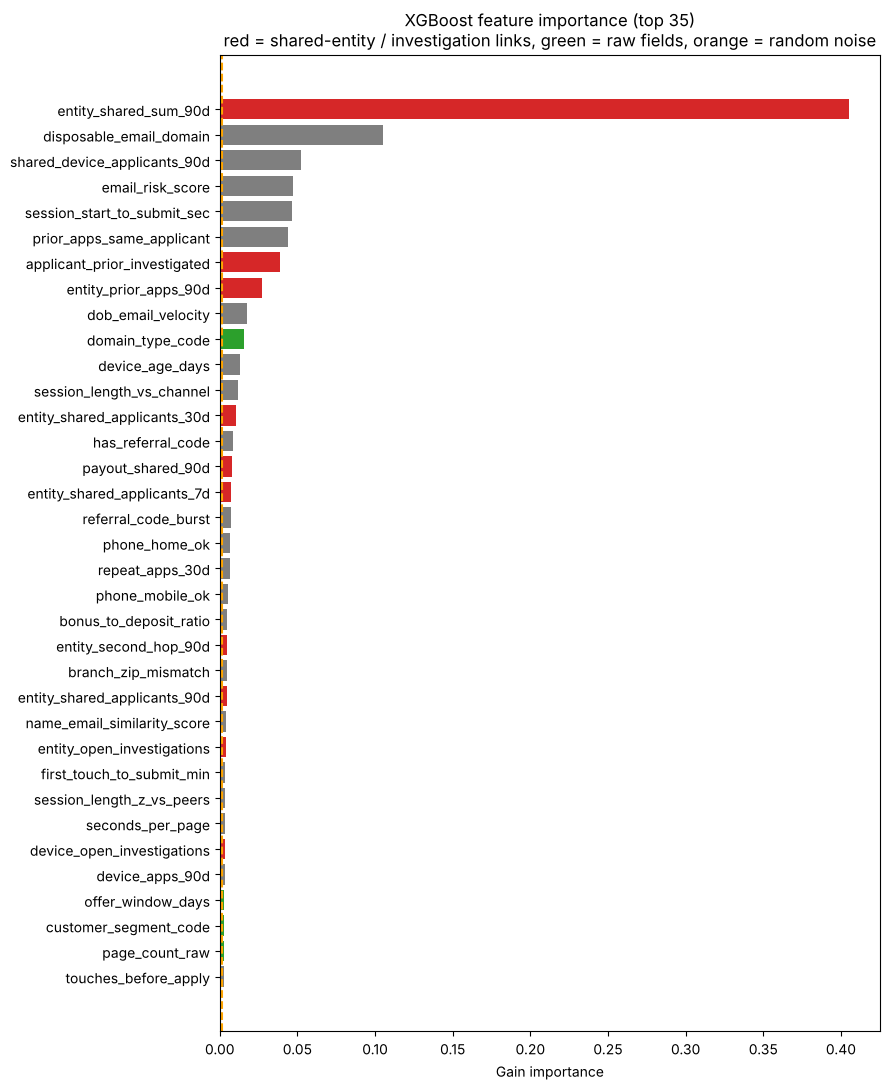

,category,xgb_importance,above_random_noise
feature,,,
entity_shared_sum_90d,Entity links (new),0.3810,True
disposable_email_domain,Identity & email,0.1312,True
session_start_to_submit_sec,Application behavior,0.0541,True
shared_device_applicants_90d,Device & network,0.0492,True
prior_apps_same_applicant,Application behavior,0.0456,True
applicant_prior_investigated,Open investigations (HW5),0.0455,True
email_risk_score,Identity & email,0.0274,True
entity_prior_apps_90d,Entity links (new),0.0272,True
dob_email_velocity,Identity & email,0.0191,True


In [18]:
imp = pd.Series(xgb_final.feature_importances_, index=FEATURES, name="gain_importance").sort_values(ascending=False)
X_r = X_tr.copy(); rng = np.random.default_rng(SEED); X_r["random_noise"] = rng.normal(size=len(X_r))
xgb_r = make_xgb(best_params, N_FINAL).fit(X_r, y_tr)
imp_r = pd.Series(xgb_r.feature_importances_, index=X_r.columns).sort_values(ascending=False)
noise_level = imp_r["random_noise"]
catalog["xgb_importance"] = imp
catalog["above_random_noise"] = catalog["xgb_importance"] > noise_level
print(f"Random-noise importance = {noise_level:.4f}. {int(catalog['above_random_noise'].sum())} of {len(FEATURES)} features score above it.")
print("Below the noise line:", ", ".join(catalog.index[~catalog["above_random_noise"]]))

fig, ax = plt.subplots(figsize=(9, 11))
top = imp_r.head(35)[::-1]
def _color(f):
    if f == "random_noise": return "orange"
    cat = catalog.loc[f, "category"]
    return "tab:red" if cat.startswith("Entity") or cat.startswith("Open") else ("tab:green" if "HW5" in cat else "tab:gray")
ax.barh(top.index, top.values, color=[_color(f) for f in top.index])
ax.axvline(noise_level, ls="--", color="orange"); ax.set_xlabel("Gain importance")
ax.set_title("XGBoost feature importance (top 35)\nred = shared-entity / investigation links, green = raw fields, orange = random noise")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_xgb_importance.png", dpi=150); plt.show()
catalog.sort_values("xgb_importance", ascending=False).to_csv(f"{OUT_DIR}/feature_catalog.csv")
catalog.sort_values("xgb_importance", ascending=False).head(15).style.format({"xgb_importance": "{:.4f}"})

In [19]:
# Importance summed by feature group
fam = catalog.groupby("category")["xgb_importance"].sum().sort_values(ascending=False)
print(fam.round(3).to_string())

category
Entity links (new)              0.455
Identity & email                0.200
Application behavior            0.130
Device & network                0.071
Open investigations (HW5)       0.056
Categorical fields (HW5)        0.037
Incentive & referral            0.023
Raw application fields (HW5)    0.015
Bank velocity counts            0.006
Offer & campaign (HW5)          0.004
Financial plausibility          0.003


In [20]:
# Value added by feature engineering: features the team built vs. raw fields used as given vs. the bank's own counts
BANK_SUPPLIED = ["dob_email_velocity", "device_distinct_emails_8w_f", "zip_count_4w", "velocity_6h", "velocity_24h",
                 "velocity_4w", "bank_branch_count_8w"]
RAW_CATS = ["Raw application fields (HW5)", "Categorical fields (HW5)"]
cat_of = catalog["category"].reindex(FEATURES)
src = pd.Series(np.where(cat_of.isin(RAW_CATS), "Raw application fields, used as given",
                np.where(pd.Index(FEATURES).isin(BANK_SUPPLIED), "Bank's own pre-computed counts",
                         "Engineered by the team from HW3 ideas")), index=FEATURES)
imp_all = pd.Series(xgb_final.feature_importances_, index=FEATURES)
top10 = imp_all.sort_values(ascending=False).index[:10]
eng_tbl = pd.DataFrame({"features": src.value_counts(),
                        "share of XGBoost importance": imp_all.groupby(src).sum().round(3),
                        "in the ten strongest": src[top10].value_counts()}).fillna(0)
eng_tbl["in the ten strongest"] = eng_tbl["in the ten strongest"].astype(int)
eng_tbl = eng_tbl.sort_values("share of XGBoost importance", ascending=False)
display(eng_tbl)

,features,share of XGBoost importance,in the ten strongest
Engineered by the team from HW3 ideas,75,0.920,9
"Raw application fields, used as given",28,0.052,0
Bank's own pre-computed counts,7,0.027,1


### Partial dependence (Deck 9)
XGBoost has no coefficients; these plots show how predicted fraud risk changes with one feature.

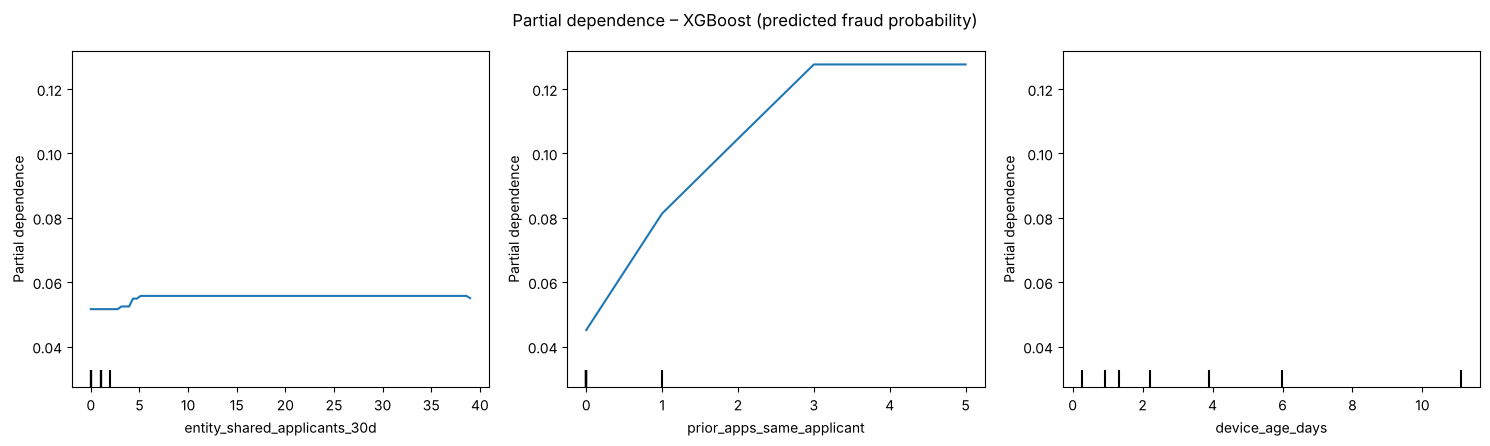

In [21]:
pdp_feats = [f for f in ["entity_shared_applicants_30d", "entity_open_investigations", "credit_risk_score_raw", "prior_apps_same_applicant",
                         "device_age_days", "entity_second_hop_90d", "payout_shared_90d", "referral_code_burst", "device_apps_90d"]
             if f in imp.head(30).index][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
PartialDependenceDisplay.from_estimator(xgb_final, X_tr.sample(20000, random_state=SEED), pdp_feats, kind="average",
                                        percentiles=(0.01, 0.99), ax=axes.ravel()[:len(pdp_feats)], n_jobs=-1)
for a in axes.ravel():
    lo, hi = a.get_ylim(); a.set_ylim(lo - 0.15 * (hi - lo), hi)        # keep flat curves clear of the rug marks
plt.suptitle("Partial dependence – XGBoost (predicted fraud probability)"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_xgb_pdp.png", dpi=150); plt.show()

## 7. Random forest (Deck 9)
Many deep trees, each on a bootstrap sample with a random subset of features at each split; predictions are averaged.
Tuned with Optuna on the same validation slice: features tried per split (`max_features`), tree depth and minimum leaf
size. 100 trees per trial during tuning, 600 in the final model.

In [22]:
from sklearn.ensemble import RandomForestClassifier

def make_rf(params, n_estimators, oob=False):
    return RandomForestClassifier(**params, n_estimators=n_estimators, random_state=SEED, n_jobs=-1, oob_score=oob)



In [23]:
def rf_objective(trial):
    params = dict(
        max_features=trial.suggest_int("max_features", 4, 40),
        max_depth=trial.suggest_categorical("max_depth", [8, 12, 16, 20, 30, None]),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 60, log=True),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 40, log=True),
    )
    m = make_rf(params, 100).fit(X_fit, y_fit)          # 100 trees are enough to rank settings; the final forest uses 600
    return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])

t0 = time.time()
rf_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
rf_study.optimize(rf_objective, n_trials=20, show_progress_bar=False)
rf_params = rf_study.best_params
print(f"Best validation AUC: {rf_study.best_value:.4f} after {len(rf_study.trials)} trials ({(time.time()-t0)/60:.1f} min)")
print("Best parameters:", rf_params)
rdf = rf_study.trials_dataframe()
rdf.sort_values("value", ascending=False)[["number", "value"] + [c for c in rdf.columns if c.startswith("params_")]].head(6).round(4)

Best validation AUC: 0.8673 after 20 trials (14.4 min)
Best parameters: {'max_features': 16, 'max_depth': 16, 'min_samples_leaf': 16, 'min_samples_split': 37}


,number,value,params_max_depth,params_max_features,params_min_samples_leaf,params_min_samples_split
15,15,0.8673,16.0,16,16,37
0,0,0.8670,16.0,11,23,35
16,16,0.8669,16.0,13,6,36
12,12,0.8668,16.0,16,42,29
11,11,0.8668,16.0,11,57,12
7,7,0.8666,20.0,11,17,10


Final random forest (600 trees) fit in 835s | OOB accuracy 0.9493
Train AUC (in-sample)      : 0.9218   (forests fit training rows almost perfectly; judge by CV/test)
5-fold CV AUC (train)      : 0.8685 ± 0.0042
Test AUC                   : 0.8683
Sep 2026 check AUC         : 0.8922


Random-noise importance (RF) = 0.0078; 42 of 110 features above it.
Top-15 features shared by XGBoost and random forest (10): ['applicant_prior_investigated', 'device_age_days', 'entity_prior_apps_90d', 'entity_shared_applicants_30d', 'entity_shared_sum_90d', 'payout_shared_90d', 'prior_apps_same_applicant', 'session_length_vs_channel', 'session_start_to_submit_sec', 'shared_device_applicants_90d']


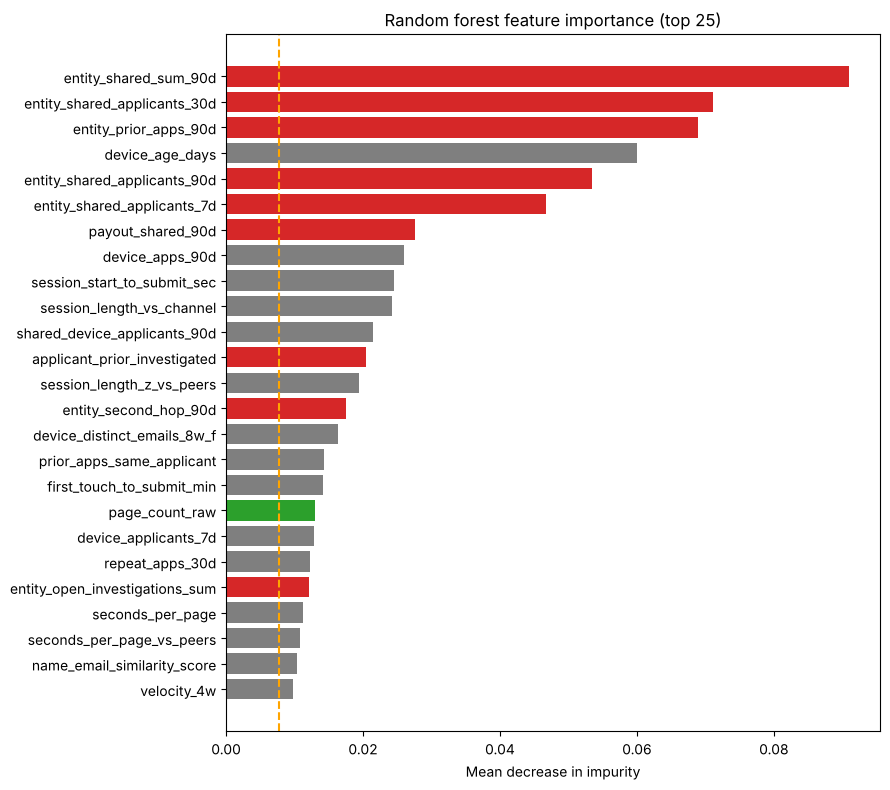

In [24]:
t0 = time.time()
rf_final = make_rf(rf_params, 600, oob=True).fit(X_tr, y_tr)
train["p_rf"] = rf_final.predict_proba(X_tr)[:, 1]
test["p_rf"]  = rf_final.predict_proba(X_te)[:, 1]
test2["p_rf"] = rf_final.predict_proba(X_t2)[:, 1]
rf_cv = cross_val_score(make_rf(rf_params, 300), X_tr, y_tr, cv=cv, scoring="roc_auc")
print(f"Final random forest (600 trees) fit in {time.time()-t0:.0f}s | OOB accuracy {rf_final.oob_score_:.4f}")
print(f"Train AUC (in-sample)      : {roc_auc_score(y_tr, train['p_rf']):.4f}   (forests fit training rows almost perfectly; judge by CV/test)")
print(f"5-fold CV AUC (train)      : {rf_cv.mean():.4f} ± {rf_cv.std():.4f}")
print(f"Test AUC                   : {roc_auc_score(y_te, test['p_rf']):.4f}")
print(f"Sep 2026 check AUC         : {roc_auc_score(y_t2, test2['p_rf']):.4f}")

# importance (mean decrease in impurity, Gini) with the random-noise check, and agreement with XGBoost's ranking
rf_r = make_rf(rf_params, 300).fit(X_r, y_tr)
imp_rf = pd.Series(rf_r.feature_importances_, index=X_r.columns).sort_values(ascending=False)
catalog["rf_importance"] = pd.Series(rf_final.feature_importances_, index=FEATURES)
catalog["rf_above_random_noise"] = catalog["rf_importance"] > imp_rf["random_noise"]
print(f"Random-noise importance (RF) = {imp_rf['random_noise']:.4f}; {int(catalog['rf_above_random_noise'].sum())} of {len(FEATURES)} features above it.")
top_x, top_r = set(catalog["xgb_importance"].nlargest(15).index), set(catalog["rf_importance"].nlargest(15).index)
print(f"Top-15 features shared by XGBoost and random forest ({len(top_x & top_r)}): {sorted(top_x & top_r)}")
fig, ax = plt.subplots(figsize=(9, 8))
top = imp_rf.head(25)[::-1]
ax.barh(top.index, top.values, color=["orange" if f == "random_noise" else _color(f) for f in top.index])
ax.axvline(imp_rf["random_noise"], ls="--", color="orange"); ax.set_xlabel("Mean decrease in impurity"); ax.set_title("Random forest feature importance (top 25)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_rf_importance.png", dpi=150); plt.show()
catalog.to_csv(f"{OUT_DIR}/feature_catalog.csv")

MODELS = [("HW4 logistic (refit)", "p_logit", "tab:blue"), ("Random forest", "p_rf", "tab:green"), ("XGBoost", "p_xgb", "tab:red")]

## 8. Assessment (Deck 7)
### AUC, Somers' D and ROC curves

split,Train,Test,Sep 2026 check
model,,,
HW4 logistic (refit),0.8427,0.8380,0.8764
Random forest,0.9218,0.8683,0.8922
XGBoost,0.8789,0.8702,0.8899


split,Train,Test,Sep 2026 check
model,,,
HW4 logistic (refit),0.6853,0.6761,0.7528
Random forest,0.8435,0.7366,0.7845
XGBoost,0.7578,0.7405,0.7797


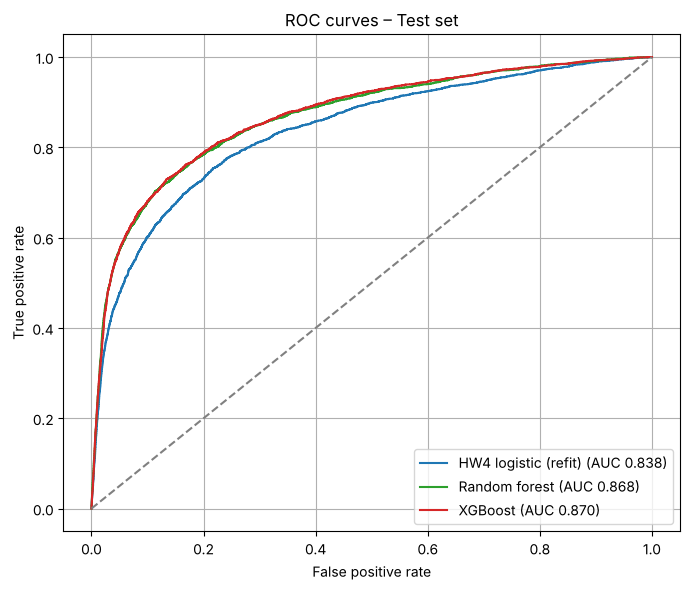

In [25]:
def somers(y, p): return 2 * roc_auc_score(y, p) - 1
rows = []
for name, col in [(n, c) for n, c, _ in MODELS]:
    for split, df in [("Train", train), ("Test", test), ("Sep 2026 check", test2)]:
        rows.append({"model": name, "split": split, "AUC (c-statistic)": roc_auc_score(df["fraud"], df[col]),
                     "Somers' D": somers(df["fraud"], df[col]), "average precision": average_precision_score(df["fraud"], df[col])})
auc_tbl = pd.DataFrame(rows).pivot(index="model", columns="split", values="AUC (c-statistic)")[["Train", "Test", "Sep 2026 check"]]
auc_tbl.to_csv(f"{OUT_DIR}/auc_table.csv")
display(auc_tbl.round(4))
display(pd.DataFrame(rows).pivot(index="model", columns="split", values="Somers' D")[["Train", "Test", "Sep 2026 check"]].round(4))

fig, ax = plt.subplots(figsize=(7, 6))
for name, col, c in MODELS:
    fpr, tpr, _ = roc_curve(test["fraud"], test[col]); ax.plot(fpr, tpr, color=c, label=f"{name} (AUC {roc_auc_score(test['fraud'], test[col]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray"); ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves – Test set"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_roc.png", dpi=150); plt.show()

### Cut-offs: Youden, F1 and cost
**Costs** come from the bank's `cost_value_parameters` (base scenario), as in HW4. Each missed fraud is charged only
what **that** application could have cost, using the offer in force on its date:

- **Missed fraud (false negative):** the new-account bonus of the application's offer ($200 under the New Money Bonus,
  $0 before July 2026) + the referrer reward of that offer **only if a referral code was used** + $57.15 onboarding, KYC,
  identity check and card + about 4 hours of investigation at $62/hour (an assumption; case hours are not recorded).
- **Good customer sent to review (false positive) ≈ $80:** $48 manual review + the value lost when reviewed good applicants
  walk away (≈16% abandon × ≈$197 of 24-month customer value).
- **Conservative check:** missed fraud = bonus (if offered) + onboarding, KYC and identity check only; false positive = $48.

The cut-off is chosen on the **training** set and evaluated on the test set.

In [26]:
params = load("cost_value_parameters"); base = params[(params["scenario"] == "base") & (params["effective_date"] == "2025-01-01")].set_index("parameter_name")["parameter_value"]
ONBOARD = base[["onboarding_cost_usd", "kyc_vendor_fee_usd", "identity_check_fee_usd", "card_issuance_cost_usd"]].sum()
ONBOARD_LOW = base[["onboarding_cost_usd", "kyc_vendor_fee_usd", "identity_check_fee_usd"]].sum()
INVESTIGATION = 4 * base["investigation_hourly_cost_usd"]          # assumption: about 4 hours per confirmed case
ABANDON_RATE, CUSTOMER_VALUE_24M = 0.1637, 196.93
COST_FP = base["manual_review_cost_usd"] + ABANDON_RATE * CUSTOMER_VALUE_24M
COST_FP_LOW = base["manual_review_cost_usd"]

for df in (train, test, test2):
    df["cost_if_missed"] = (df["offer_bonus_usd"] + df["offer_referrer_reward_usd"] * df["has_referral_code"]
                            + ONBOARD + INVESTIGATION)
    df["cost_if_missed_low"] = df["offer_bonus_usd"] + ONBOARD_LOW
ft_cost = test.loc[test["fraud"] == 1, "cost_if_missed"]
print(f"Cost of a missed fraud (test set): ${ft_cost.min():,.2f} to ${ft_cost.max():,.2f}, average ${ft_cost.mean():,.2f}")
print(f"Cost of a false positive: ${COST_FP:,.2f}  (conservative: ${COST_FP_LOW:,.2f})")

def classify(df, col, cut, low=False):
    miss_cost = df["cost_if_missed_low"] if low else df["cost_if_missed"]
    cfp = COST_FP_LOW if low else COST_FP
    pred = df[col] > cut; y = df["fraud"] == 1
    tp, fp, fn, tn = int((pred & y).sum()), int((pred & ~y).sum()), int((~pred & y).sum()), int((~pred & ~y).sum())
    return {"cut-off": round(cut, 3), "flagged": int(pred.sum()), "flagged %": pred.mean(), "recall (fraud caught)": tp / (tp + fn),
            "precision": tp / max(tp + fp, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1), "specificity": tn / (tn + fp),
            "fraud caught": tp, "good customers flagged": fp, "fraud missed": fn,
            "missed fraud cost": miss_cost[~pred & y].sum(), "false positive cost": fp * cfp,
            "total cost": miss_cost[~pred & y].sum() + fp * cfp}

def no_model_cost(df, low=False):
    """Approve everyone: every fraud is missed."""
    return df.loc[df["fraud"] == 1, "cost_if_missed_low" if low else "cost_if_missed"].sum()

def best_cuts(df, col):
    fpr, tpr, thr = roc_curve(df["fraud"], df[col]); youden = thr[np.argmax(tpr - fpr)]
    grid = np.arange(0.01, 0.80, 0.01)
    f1 = max(grid, key=lambda c: classify(df, col, c)["F1"])
    cost = min(grid, key=lambda c: classify(df, col, c)["total cost"])
    cost_low = min(grid, key=lambda c: classify(df, col, c, low=True)["total cost"])
    return {"Youden": youden, "F1": f1, "Cost-based": cost, "Cost-based (conservative costs)": cost_low}

cuts = {m: best_cuts(train, c) for m, c, _ in MODELS}
rows = []
for m, c, _ in MODELS:
    for rule, cut in cuts[m].items():
        rows.append({"model": m, "rule": rule, **classify(test, c, cut, low=(rule == "Cost-based (conservative costs)"))})
cut_tbl = pd.DataFrame(rows).set_index(["model", "rule"])
cut_tbl.to_csv(f"{OUT_DIR}/cutoff_table_test.csv")
print(f"\nTest-set cost with NO model (all fraud missed): ${no_model_cost(test):,.0f}  (conservative costs: ${no_model_cost(test, low=True):,.0f})")
print("Rows for the conservative cut-off are priced at conservative costs; all other rows at the main costs.")
cut_tbl.style.format({"cut-off": "{:.3f}", "flagged": "{:,}", "flagged %": "{:.1%}", "recall (fraud caught)": "{:.1%}", "precision": "{:.1%}",
                      "F1": "{:.3f}", "specificity": "{:.1%}", "missed fraud cost": "${:,.0f}", "false positive cost": "${:,.0f}", "total cost": "${:,.0f}"})

Cost of a missed fraud (test set): $305.15 to $505.15, average $349.17
Cost of a false positive: $80.24  (conservative: $48.00)



Test-set cost with NO model (all fraud missed): $983,963  (conservative costs: $266,014)
Rows for the conservative cut-off are priced at conservative costs; all other rows at the main costs.


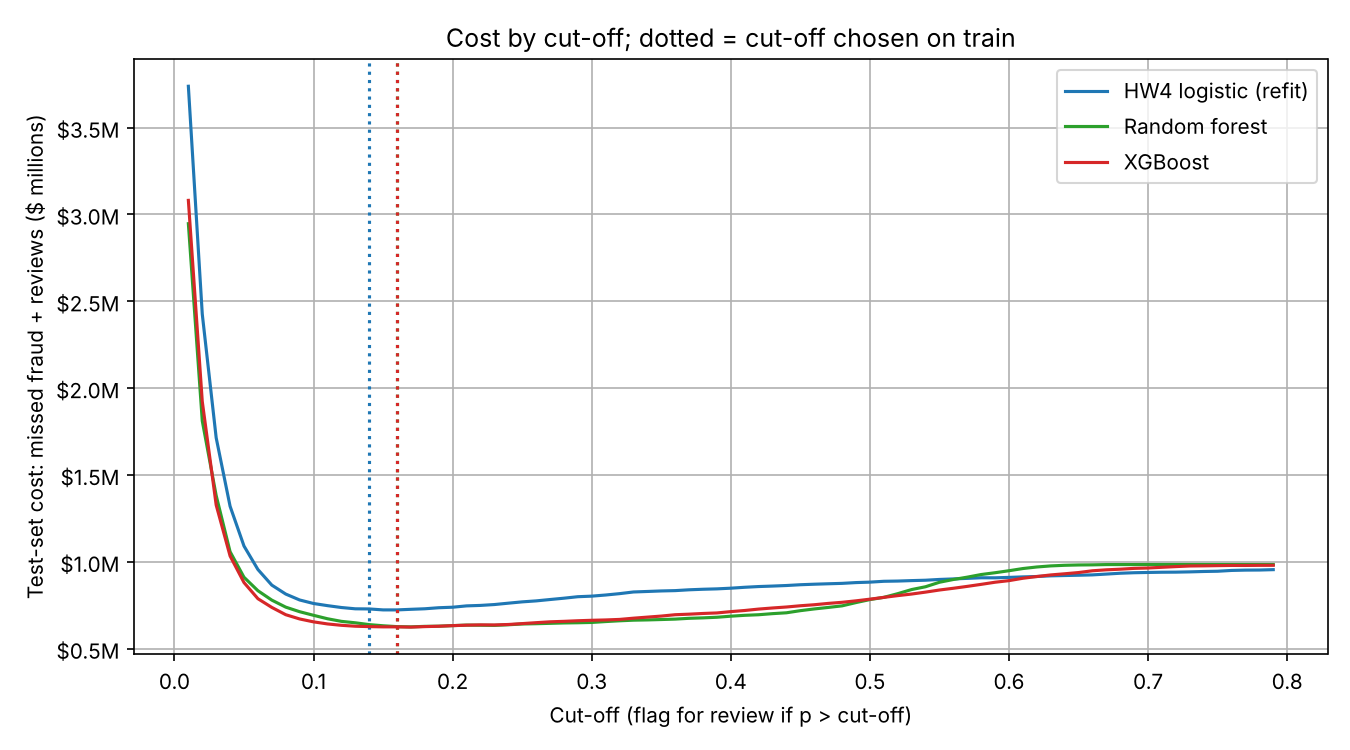

In [27]:
# Cost curve: total test-set cost at every cut-off, all three models (y-axis shown in $ millions)
from matplotlib.ticker import FuncFormatter
grid = np.arange(0.01, 0.80, 0.01)
fig, ax = plt.subplots(figsize=(9, 5))
for m, c, colr in MODELS:
    ax.plot(grid, [classify(test, c, g)["total cost"] for g in grid], color=colr, label=m)
    ax.axvline(cuts[m]["Cost-based"], color=colr, ls=":")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1e6:.1f}M"))
ax.set(xlabel="Cut-off (flag for review if p > cut-off)", ylabel="Test-set cost: missed fraud + reviews ($ millions)", title="Cost by cut-off; dotted = cut-off chosen on train")
ax.legend(); ax.grid(True); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_cost_curve.png", dpi=150); plt.show()

### Confusion matrix, review capacity, lift and gains (XGBoost at its cost-based cut-off)

XGBoost cost-based cut-off: 0.16


Flagged for review,0,1
Actual fraud,,
0,48121,2059
1,1295,1523



Fraud-review capacity, Aug 2026: 21,551 cases | already arriving: 3,310 | room: 18,241
XGBoost flags 4,428 of 37,544 August 2026 applications (11.8%) → fits within capacity


HW4 logistic (refit)                                          Random forest                                           XGBoost                    \
                 top % precision   lift share of fraud captured         top % precision    lift share of fraud captured   top % precision    lift   
0                 0.01     0.526  9.883                   0.099          0.01     0.575  10.808                   0.108    0.01     0.554  10.417   
1                 0.05     0.424  7.966                   0.398          0.05     0.492   9.251                   0.462    0.05     0.487   9.159   
2                 0.10     0.290  5.455                   0.545          0.10     0.332   6.247                   0.625    0.10     0.334   6.275   
3                 0.20     0.187  3.515                   0.703          0.20     0.201   3.781                   0.756    0.20     0.202   3.806   

                           
  share of fraud captured  
0                   0.104  
1                   0.458  
2                   0.627  
3                   0.761

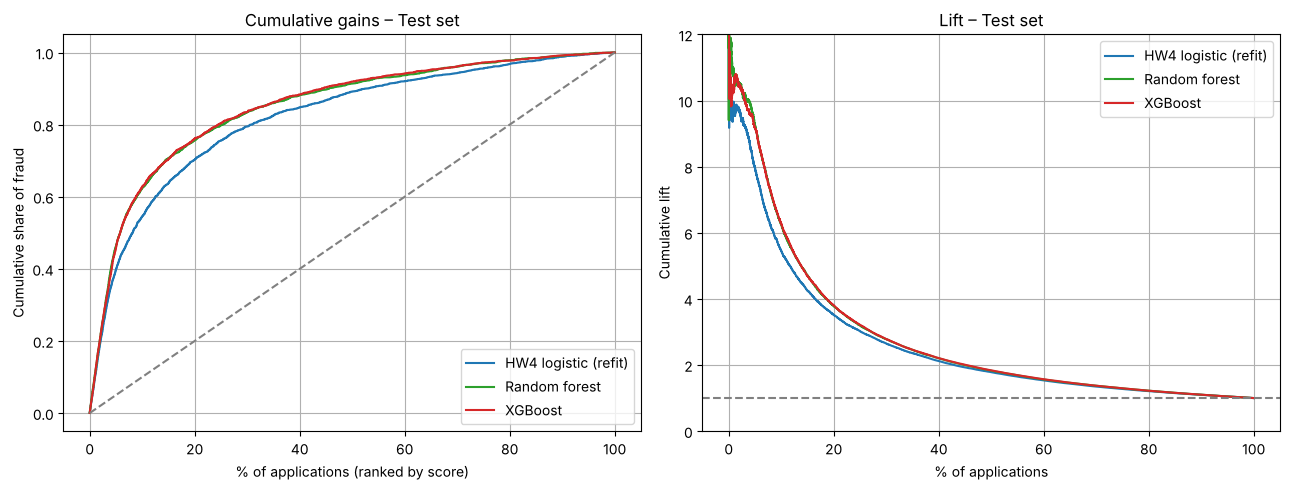

In [28]:
CUT = cuts["XGBoost"]["Cost-based"]
test["pred_xgb"] = (test["p_xgb"] > CUT).astype(int)
print(f"XGBoost cost-based cut-off: {CUT:.2f}")
display(pd.crosstab(test["fraud"], test["pred_xgb"], rownames=["Actual fraud"], colnames=["Flagged for review"]))

staffing, teams, queue = load("reviewer_team_staffing"), load("reviewer_teams"), load("daily_queue_metrics")
fraud_teams = teams.loc[teams["team_type"] == "fraud_review", "reviewer_team_id"]
capacity = staffing[staffing["staffing_date"].str.startswith("2026-08") & staffing["reviewer_team_id"].isin(fraud_teams)]["scheduled_capacity_cases"].sum()
arrived = queue[queue["queue_date"].str.startswith("2026-08") & queue["reviewer_team_id"].isin(fraud_teams)]["cases_arrived"].sum()
# score EVERY August 2026 application (train and test rows) to see a full month of review volume
aug_all = pd.concat([train, test]); aug_all = aug_all[aug_all["month"] == "2026-08"]
flagged = int((aug_all["p_xgb"] > CUT).sum())
print(f"\nFraud-review capacity, Aug 2026: {capacity:,} cases | already arriving: {arrived:,} | room: {capacity - arrived:,}")
print(f"XGBoost flags {flagged:,} of {len(aug_all):,} August 2026 applications ({flagged / len(aug_all):.1%}) → "
      f"{'fits' if flagged <= capacity - arrived else 'does NOT fit'} within capacity")

def lift_table(df, col):
    r = df.sort_values(col, ascending=False).reset_index(drop=True)
    return pd.DataFrame([{"top %": d, "precision": r["fraud"][: int(d * len(r))].mean(), "lift": r["fraud"][: int(d * len(r))].mean() / r["fraud"].mean(),
                          "share of fraud captured": r["fraud"][: int(d * len(r))].sum() / r["fraud"].sum()} for d in [0.01, 0.05, 0.10, 0.20]])
lt = pd.concat({m: lift_table(test, c) for m, c, _ in MODELS}, axis=1)
lt.to_csv(f"{OUT_DIR}/lift_table_test.csv")
display(lt.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for m, c, colr in MODELS:
    r = test.sort_values(c, ascending=False).reset_index(drop=True); pct = np.arange(1, len(r) + 1) / len(r)
    gains = r["fraud"].cumsum() / r["fraud"].sum()
    ax[0].plot(pct * 100, gains, color=colr, label=m); ax[1].plot(pct * 100, gains / pct, color=colr, label=m)
ax[0].plot([0, 100], [0, 1], "--", color="gray"); ax[0].set(xlabel="% of applications (ranked by score)", ylabel="Cumulative share of fraud", title="Cumulative gains – Test set"); ax[0].legend(); ax[0].grid(True)
ax[1].axhline(1, ls="--", color="gray"); ax[1].set(xlabel="% of applications", ylabel="Cumulative lift", title="Lift – Test set", ylim=(0, 12)); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_lift_gains.png", dpi=150); plt.show()

### Fraud caught by type, and the bank's current score
`fraud_score_at_event` is the bank's current score at its automatic decision, used only for comparison.

In [29]:
types = inv_status[inv_status["status"] == "confirmed"].drop_duplicates("application_id")[["application_id", "fraud_type"]]
ft = test[test["fraud"] == 1].merge(types, on="application_id", how="left")
for m, c, _ in MODELS:
    ft[m] = (ft[c] > cuts[m]["Cost-based"]).astype(int)
ft = ft.groupby("fraud_type").agg(fraud_cases=("fraud", "size"), **{f"recall: {m}": (m, "mean") for m, _, _ in MODELS})
ft.to_csv(f"{OUT_DIR}/recall_by_fraud_type.csv")
display(ft.style.format({c: "{:.1%}" for c in ft.columns if c.startswith("recall")}))

legacy = load("decisions_reviews")[["application_id", "event_type", "fraud_score_at_event"]]
legacy = legacy[legacy["event_type"] == "auto_decision"].drop_duplicates("application_id")
bench = test.merge(legacy, on="application_id", how="inner")
k = int(0.05 * len(bench))
print(f"Applications compared: {len(bench):,}")
for name, col in [("Bank's current score", "fraud_score_at_event")] + [(n, c) for n, c, _ in MODELS]:
    top5 = bench.sort_values(col, ascending=False)["fraud"]
    print(f"{name:22s}: AUC {roc_auc_score(bench['fraud'], bench[col]):.3f} | fraud found in the riskiest 5%: {top5[:k].sum() / top5.sum():.1%}")

,fraud_cases,recall: HW4 logistic (refit),recall: Random forest,recall: XGBoost
fraud_type,,,,
bonus_abuse,833,63.6%,76.0%,73.9%
first_party,402,19.9%,18.4%,18.2%
stolen_identity,856,38.6%,40.1%,37.4%
synthetic_identity,727,47.5%,71.7%,70.7%


Applications compared: 52,998
Bank's current score  : AUC 0.645 | fraud found in the riskiest 5%: 6.1%


HW4 logistic (refit)  : AUC 0.838 | fraud found in the riskiest 5%: 39.8%
Random forest         : AUC 0.868 | fraud found in the riskiest 5%: 46.2%
XGBoost               : AUC 0.870 | fraud found in the riskiest 5%: 45.8%


## 9. Model comparison
Each model at its own cost-based cut-off (chosen on the training set), scored on the test set and on September 2026.

In [30]:
rows = []
for name, col, _ in MODELS:
    cut = cuts[name]["Cost-based"]; b = classify(test, col, cut); b2 = classify(test2, col, cut)
    rows.append({"model": name, "features used": len(HW4_VARS) + len(HW4_FLAGS) if "logistic" in name else len(FEATURES),
                 "train AUC": roc_auc_score(y_tr, train[col]), "test AUC": roc_auc_score(y_te, test[col]), "Sep 2026 AUC": roc_auc_score(y_t2, test2[col]),
                 "cut-off": cut, "flagged %": b["flagged %"], "recall": b["recall (fraud caught)"], "precision": b["precision"], "F1": b["F1"],
                 "good customers flagged": b["good customers flagged"], "fraud missed": b["fraud missed"], "test cost": b["total cost"],
                 "Sep 2026 cost (same cut-off)": b2["total cost"]})
comp = pd.DataFrame(rows).set_index("model")
comp.loc["No model (approve everything)", ["test cost", "Sep 2026 cost (same cut-off)"]] = [no_model_cost(test), no_model_cost(test2)]
comp.to_csv(f"{OUT_DIR}/model_comparison.csv")
L, G, R = comp.loc["HW4 logistic (refit)"], comp.loc["XGBoost"], comp.loc["Random forest"]
n_fraud = int(test["fraud"].sum())
for name, M in [("Random forest", R), ("XGBoost", G)]:
    saved = L["test cost"] - M["test cost"]
    print(f"{name} vs HW4 logistic (test set, each at its own cost-based cut-off): cost ${M['test cost']:,.0f} vs ${L['test cost']:,.0f} "
          f"-> ${saved:,.0f} lower ({saved / L['test cost']:.1%}); fraud caught {n_fraud - int(M['fraud missed']):,} vs {n_fraud - int(L['fraud missed']):,}; "
          f"good customers reviewed {int(M['good customers flagged']):,} vs {int(L['good customers flagged']):,}")
comp.style.format({"train AUC": "{:.3f}", "test AUC": "{:.3f}", "Sep 2026 AUC": "{:.3f}", "cut-off": "{:.2f}", "flagged %": "{:.1%}", "recall": "{:.1%}",
                   "precision": "{:.1%}", "F1": "{:.3f}", "test cost": "${:,.0f}", "Sep 2026 cost (same cut-off)": "${:,.0f}", "features used": "{:.0f}",
                   "good customers flagged": "{:,.0f}", "fraud missed": "{:,.0f}"}, na_rep="")

Random forest vs HW4 logistic (test set, each at its own cost-based cut-off): cost $626,269 vs $728,093 -> $101,824 lower (14.0%); fraud caught 1,571 vs 1,285; good customers reviewed 2,262 vs 2,224
XGBoost vs HW4 logistic (test set, each at its own cost-based cut-off): cost $624,928 vs $728,093 -> $103,165 lower (14.2%); fraud caught 1,523 vs 1,285; good customers reviewed 2,059 vs 2,224


,features used,train AUC,test AUC,Sep 2026 AUC,cut-off,flagged %,recall,precision,F1,good customers flagged,fraud missed,test cost,Sep 2026 cost (same cut-off)
model,,,,,,,,,,,,,
HW4 logistic (refit),20,0.843,0.838,0.876,0.14,6.6%,45.6%,36.6%,0.406,"2,224","1,533","$728,093","$591,599"
Random forest,110,0.922,0.868,0.892,0.16,7.2%,55.7%,41.0%,0.472,"2,262","1,247","$626,269","$526,214"
XGBoost,110,0.879,0.870,0.890,0.16,6.8%,54.0%,42.5%,0.476,"2,059","1,295","$624,928","$529,426"
No model (approve everything),,,,,,,,,,,,"$983,963","$890,306"


In [31]:
# Save the scored test set and the final model
test[["application_id", "month", "application_channel", "fraud", "p_logit", "p_rf", "p_xgb"]].to_csv(f"{OUT_DIR}/scored_test.csv", index=False)
xgb_final.save_model(f"{OUT_DIR}/xgb_fraud_model.json")
print("Saved:", sorted(os.listdir(OUT_DIR)))

Saved: ['auc_table.csv', 'cutoff_table_test.csv', 'feature_catalog.csv', 'fig_cost_curve.png', 'fig_lift_gains.png', 'fig_rf_importance.png', 'fig_roc.png', 'fig_xgb_importance.png', 'fig_xgb_pdp.png', 'lift_table_test.csv', 'model_comparison.csv', 'recall_by_fraud_type.csv', 'scored_test.csv', 'xgb_fraud_model.json']


## Summary
- **Final model: XGBoost, reviewing applications that score above 0.16.** On the test set (52,998 applications) it reaches an
  AUC of 0.870 and catches 54% of fraud while reviewing 6.8% of applications. Total cost is $624,928, compared with
  $728,093 for the refit HW4 logistic regression (14% lower) and $983,963 with no model (36% lower).
- **Random forest is close** (AUC 0.868, $626,269). XGBoost is preferred because it overfits less (train 0.879 vs test 0.870,
  compared with 0.922 vs 0.868 for the forest), flags fewer good customers at its cut-off, and is far faster to train.
- **Both tree models beat the HW4 logistic regression** (AUC 0.838 on the same split) and hold up on September 2026 (0.890 and 0.892).
- **Feature engineering carries the model:** features the team built hold 92% of XGBoost's importance; raw application
  fields hold 5%. Shared phone/address/payout/device links are the strongest group (46%).
- **Trade-off:** the logistic regression is easier to explain (odds ratios); XGBoost explains itself through feature
  importance and partial dependence instead.